# Learning Rate Schedulers: Head to Head
**CPSC 471 · Applied AI** — companion exercise to the *Learning Rate Schedulers* lecture

We train **the same small network, on the same data, from the same starting weights** three times:

1. **No scheduler**: a fixed learning rate
2. **Cosine annealing**: smooth decay from the starting rate to near zero (`scheduler.step()` once per **epoch**)
3. **One cycle**: ramp up, then down (`scheduler.step()` once per **batch**)

Then we plot the learning rate, training loss, and validation loss for all three. Runs in about a minute on a CPU.

## 1) Data: handwritten digits (built into scikit-learn, no download)

In [1]:
import copy, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

X, y = load_digits(return_X_y=True)          # 1,797 images of 8x8 pixels, digits 0-9
X = X / 16.0                                  # scale pixels to 0..1
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

to_t = lambda a, dt: torch.tensor(a, dtype=dt)
train_ds = TensorDataset(to_t(X_tr, torch.float32), to_t(y_tr, torch.long))
X_val_t, y_val_t = to_t(X_val, torch.float32), to_t(y_val, torch.long)
print(f"train: {len(train_ds)}  validation: {len(y_val)}  features: {X.shape[1]}  classes: 10")

train: 1347  validation: 450  features: 64  classes: 10


## 2) One model, one set of starting weights

In [2]:
torch.manual_seed(0)
base_model = nn.Sequential(
    nn.Linear(64, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 10),
)
initial_weights = copy.deepcopy(base_model.state_dict())   # every run starts from exactly these weights

EPOCHS, BATCH, LR = 30, 32, 0.15
loss_fn = nn.CrossEntropyLoss()

## 3) The training loop
`make_scheduler` returns the scheduler **and when to step it**: cosine steps once per epoch (like the lecture slide), one cycle steps once per batch.

Remember from the lecture: the **optimizer** uses the learning rate; the scheduler only rewrites `optimizer.param_groups[0]["lr"]`.

In [3]:
def make_scheduler(name, opt, steps_per_epoch):
    if name == "none":
        return None, None
    if name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-4), "epoch"
    if name == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS,
                                                   steps_per_epoch=steps_per_epoch), "batch"
    raise ValueError(name)

def train(name, seed=0):
    torch.manual_seed(seed)                                    # same batch order for every run
    model = copy.deepcopy(base_model)
    model.load_state_dict(initial_weights)
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9)
    sched, every = make_scheduler(name, opt, len(loader))

    hist = {"lr": [], "train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for xb, yb in loader:
            hist["lr"].append(opt.param_groups[0]["lr"])       # lr used for THIS batch
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()                                         # the optimizer uses the lr
            if every == "batch":
                sched.step()
            total += loss.item() * len(yb)
        if every == "epoch":
            sched.step()

        model.eval()
        with torch.no_grad():
            logits = model(X_val_t)
            hist["val_loss"].append(loss_fn(logits, y_val_t).item())
            hist["val_acc"].append((logits.argmax(1) == y_val_t).float().mean().item())
        hist["train_loss"].append(total / len(train_ds))
    return hist

## 4) Run all three

In [4]:
runs = {name: train(name) for name in ["none", "cosine", "onecycle"]}

print(f"{'scheduler':<10} {'final train loss':>17} {'final val loss':>15} {'final val acc':>14} {'best val acc':>13}")
for name, h in runs.items():
    print(f"{name:<10} {h['train_loss'][-1]:>17.4f} {h['val_loss'][-1]:>15.4f} "
          f"{h['val_acc'][-1]:>14.3f} {max(h['val_acc']):>13.3f}")

scheduler   final train loss  final val loss  final val acc  best val acc
none                  0.0593          0.2890          0.940         0.973
cosine                0.0035          0.1137          0.976         0.980
onecycle              0.0008          0.0726          0.982         0.984


## 5) Plot the learning rate and the loss curves

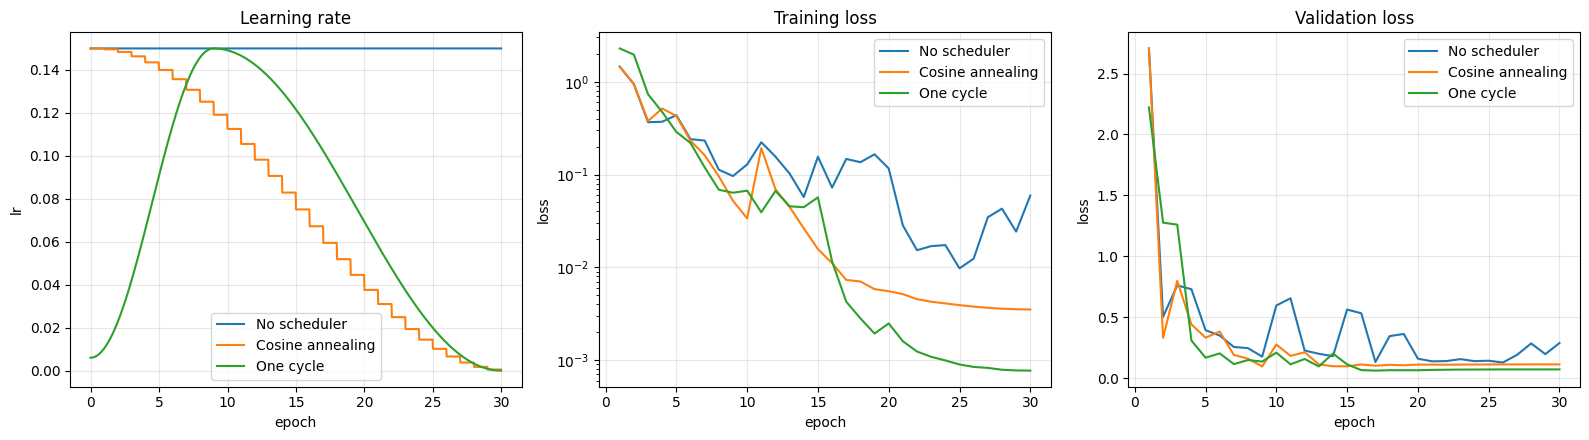

In [5]:
labels = {"none": "No scheduler", "cosine": "Cosine annealing", "onecycle": "One cycle"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for name, h in runs.items():
    steps_per_epoch = len(h["lr"]) / EPOCHS
    ax[0].plot([i / steps_per_epoch for i in range(len(h["lr"]))], h["lr"], label=labels[name])
    ax[1].plot(range(1, EPOCHS + 1), h["train_loss"], label=labels[name])
    ax[2].plot(range(1, EPOCHS + 1), h["val_loss"], label=labels[name])

ax[0].set(title="Learning rate", xlabel="epoch", ylabel="lr")
ax[1].set(title="Training loss", xlabel="epoch", ylabel="loss", yscale="log")
ax[2].set(title="Validation loss", xlabel="epoch", ylabel="loss")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

## 6) What to look for
- **Learning rate panel:** cosine steps down once per epoch (a staircase), one cycle changes every batch (a smooth hump).
- **Training loss** (log scale): the fixed rate stalls, still taking big steps at the end. Both schedulers keep going lower once their rate gets small. One cycle usually goes lowest: its warmup lets the network settle before the rate peaks.
- **Validation loss:** lowest training loss doesn't automatically mean lowest validation loss. If validation loss creeps up at the end, that's overfitting; the lecture's fix is to keep the best checkpoint (or plan fewer epochs), not to cut the schedule short.
- On a dataset this small, final **accuracies** are close (all around 97–98%). The **loss curves** show the difference more clearly, and your exact numbers will vary a little by seed.

## 7) Exercises
1. **Seeds:** rerun with `train(name, seed=s)` for 3 different seeds. Are the differences between schedulers bigger than the differences between seeds?
2. **Higher peak:** one cycle was designed for *large* rates. Rerun one cycle with `max_lr=0.3` (keep the others at 0.1). What happens?
3. **Why warmup matters:** set `LR = 0.25` for all three and run seeds 0 and 1. Which runs blow up (loss stuck near 2.3 = random guessing over 10 classes)? Cosine starts at full speed; one cycle warms up first. Connect this to why LLM training always starts with warmup.
4. **Warm restarts:** add a `"sgdr"` option using `CosineAnnealingWarmRestarts(opt, T_0=10)` stepped once per epoch. Find the restarts in the loss curves.
5. **Wrong frequency:** step `OneCycleLR` once per **epoch** instead of per batch. What do the learning-rate plot and loss do? (Hint: PyTorch eventually raises an error. Why?)